# K-Nearest Neighbours (KNN)

> Intuition: *"Tell me who your neighbours are, and I'll tell you who you are."*

**Idea:** points that are close to each other are probably similar. To predict a new point, look at the `k` training points closest to it and let them decide.

### The algorithm
Given training data $(x_1, y_1), \dots, (x_n, y_n)$ and a new point $x$:

1. Compute the distance $d(x, x_i)$ to **every** training point.
2. Keep the $k$ closest points → the neighbourhood $N_k(x)$.
3. Predict:
   - **Classification** → majority vote: $\quad \hat{y} = \text{mode}\{\, y_i : i \in N_k(x) \,\}$
   - **Regression** → average: $\quad \hat{y} = \frac{1}{k} \sum_{i \in N_k(x)} y_i$

*Weighted KNN:* closer neighbours get a bigger say, e.g. weight $w_i = 1 / d(x, x_i)$.

### Common distance functions
Let $p$ and $q$ be two points, and $j$ run over their features (e.g. x and y in 2D).
**Example:** $p = (1, 2)$ and $q = (4, 6)$ → the differences are 3 (in x) and 4 (in y).

| Name | Formula | Intuition | Example | When to use |
|---|---|---|---|---|
| **Euclidean** | $\sqrt{\sum_j (p_j - q_j)^2}$ | Length of the straight line joining the two points (Pythagoras). Squaring makes big differences count a lot. | $\sqrt{3^2 + 4^2} = 5$ | Default choice. Continuous features on similar scales (after standardising). |
| **Manhattan** | $\sum_j \lvert p_j - q_j \rvert$ | Distance when you can only move along the axes, like walking city blocks: add up the gap in every feature. | $3 + 4 = 7$ | Data with outliers (no squaring, so one big gap doesn't dominate), high-dimensional data, grid-like or count features. |
| **Chebyshev** | $\max_j \lvert p_j - q_j \rvert$ | Only the single largest gap counts; all other features are ignored. | $\max(3, 4) = 4$ | When being far off in *any one* feature is what matters, e.g. tolerance checks ("every measurement within ±2 units"). |
| **Cosine** | $1 - \dfrac{p \cdot q}{\lVert p \rVert \, \lVert q \rVert}$ | Treats points as arrows from the origin and compares only their direction. 0 = same direction, 1 = perpendicular, 2 = opposite. | $1 - \dfrac{16}{\sqrt{5}\,\sqrt{52}} \approx 0.008$ | Text and embeddings, where direction matters and length doesn't (a long and a short document on the same topic should be close). |

> The same pair of points is "far apart" under the first three metrics but almost identical under cosine. **In KNN, the metric decides who counts as a neighbour.**

### Key facts
- **No real training:** `fit()` just stores the data. KNN is a *lazy learner*; all the work happens at prediction time.
- Only two things to choose: **k** and the **distance function d**.

## 1. Building KNN from scratch
The distance function `d(p1, p2)` is passed in, so we can plug in any metric we like.

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def euclidean(p1, p2):
    return np.sqrt(np.sum((p1 - p2) ** 2))

def manhattan(p1, p2):
    return np.sum(np.abs(p1 - p2))

def chebyshev(p1, p2):
    return np.max(np.abs(p1 - p2))

def cosine(p1, p2):
    return 1 - np.dot(p1, p2) / (np.linalg.norm(p1) * np.linalg.norm(p2))


class KNN:
    def __init__(self, k=3, d=euclidean):
        self.k = k
        self.d = d

    def fit(self, X, y):
        self.X, self.y = X, y   # lazy learner: just memorise the data

    def neighbours(self, x):
        distances = [self.d(x, p) for p in self.X]
        return np.argsort(distances)[:self.k]

    def predict_one(self, x):
        labels = self.y[self.neighbours(x)]
        return Counter(labels).most_common(1)[0][0]   # ties go to the label seen first, i.e. the closer one

    def predict(self, X):
        return np.array([self.predict_one(x) for x in X])

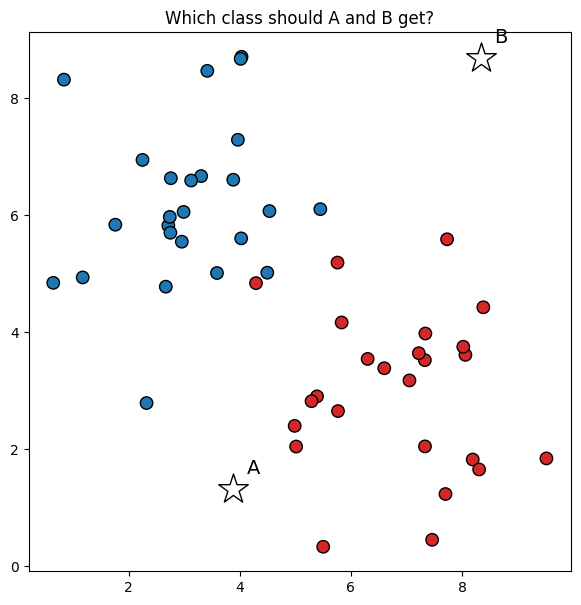

In [19]:
from sklearn.datasets import make_blobs
from matplotlib.colors import ListedColormap

# 24 training points in 2 classes, and 2 new points (A, B) to classify
X_train, y_train = make_blobs(n_samples=50, centers=[(3, 6.5), (6.5, 3)], cluster_std=1.4, random_state=11)
X_test = np.random.uniform(1, 9, size=(2, 2))   # 2 random points anywhere in the plot

cmap = ListedColormap(['tab:blue', 'tab:red'])   # class 0 = blue, class 1 = red

plt.figure(figsize=(7, 7))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap, s=80, edgecolor='k')
for name, q in zip('AB', X_test):
    plt.scatter(q[0], q[1], c='white', marker='*', s=500, edgecolor='k')
    plt.text(q[0] + 0.25, q[1] + 0.25, name, fontsize=14)
plt.title('Which class should A and B get?')
plt.show()

## 3. Our KNN in action
Change `k` and `metric`, then re-run the cell. (Re-run the cell above to get new random positions for A and B.)

Dashed lines connect A and B to their `k` nearest neighbours, and each ★ takes the colour of the class those neighbours vote for.

Predictions for A, B: [1 0]


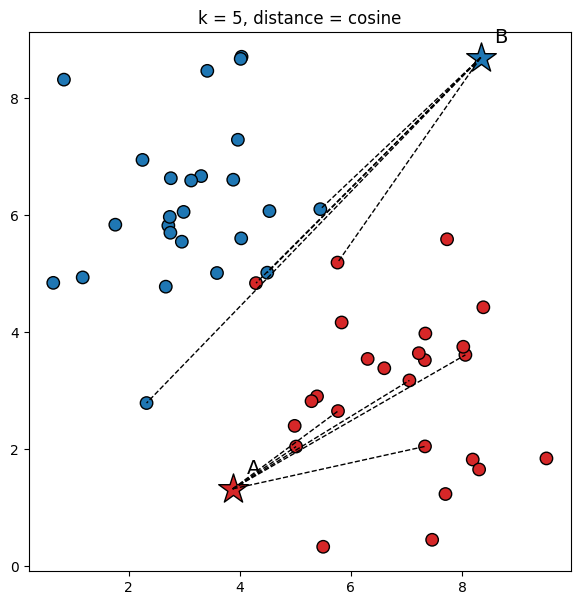

In [20]:
k = 5
metric = cosine      # try: manhattan, chebyshev, cosine, euclidean

model = KNN(k=k, d=metric)
model.fit(X_train, y_train)
print('Predictions for A, B:', model.predict(X_test))

plt.figure(figsize=(7, 7))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap, s=80, edgecolor='k')

# Dashed lines from each test point to its k nearest neighbours; the star takes its predicted colour
for name, q in zip('AB', X_test):
    for i in model.neighbours(q):
        plt.plot([q[0], X_train[i, 0]], [q[1], X_train[i, 1]], 'k--', lw=1)
    plt.scatter(q[0], q[1], c=[model.predict_one(q)], cmap=cmap, vmin=0, vmax=1, marker='*', s=500, edgecolor='k')
    plt.text(q[0] + 0.25, q[1] + 0.25, name, fontsize=14)

plt.title(f'k = {k}, distance = {metric.__name__}')
plt.show()

### Choosing k
| k | What happens | Result |
|---|---|---|
| **Small** (e.g. 1) | copies its closest point, even if that point is noise | poor test accuracy → **overfitting** (high variance) |
| **Large** (e.g. 101) | also counts far-away points that aren't really similar; at k = n it always predicts the majority class | poor test accuracy → **underfitting** (high bias) |
| **In between** | ignores noise but still follows the real shape | right balance for good test accuracy |

- In binary classification, use an **odd k** so the vote can't tie.
- A common starting point is $k \approx \sqrt{n}$.

### Choosing the distance function
- The distance defines what "close" means, so it sets the **shape of the neighbourhood**: a circle for Euclidean, a diamond for Manhattan, a square for Chebyshev.
- **Cosine** ignores how far away a point is and only looks at its direction from the origin. That's useful for text or embeddings, and very odd for our 2D points: try it above and see which neighbours A and B pick.
- **Feature scale matters.** If one feature is in thousands (salary) and another in single digits (age), the big one dominates every distance. Standardise first: $z = \dfrac{x - \mu}{\sigma}$. We'll see this on real data next.

## 5. KNN Classification with scikit-learn: Pima Indians Diabetes
768 patients, 8 medical measurements (glucose, BMI, age, ...). We predict whether the patient has diabetes (`1`) or not (`0`).

In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigree', 'Age', 'Outcome']
diabetes = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv', names=cols)
diabetes.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [22]:
missing = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
diabetes[missing] = diabetes[missing].replace(0, np.nan)
diabetes = diabetes.fillna(diabetes.median())

X_diabetes = diabetes.drop(columns='Outcome').values
y_diabetes = diabetes['Outcome'].values

In [23]:
k = 5
metric = 'euclidean'     # 'manhattan', 'chebyshev', 'cosine' 'euclidean'
weights = 'uniform'      # 'distance' 'uniform'
use_scaling = True

Xtr, Xte, ytr, yte = train_test_split(X_diabetes, y_diabetes, test_size=0.2, random_state=42, stratify=y_diabetes)
if use_scaling:
    scaler = StandardScaler().fit(Xtr)   # learn mean/std from train only
    Xtr, Xte = scaler.transform(Xtr), scaler.transform(Xte)

knn = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights)
knn.fit(Xtr, ytr)

print(f"Test accuracy:  {knn.score(Xte, yte):.3f}")

Test accuracy:  0.753


## 6. KNN Regression with scikit-learn: Auto MPG
Predict a car's fuel efficiency (**miles per gallon**) from its cylinders, horsepower, weight, etc.

Same idea as before, but instead of voting, the prediction is the **average mpg of the k nearest cars**.

In [24]:
cars = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv')
cars.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [25]:
cars = cars.drop(columns='name').dropna()
cars = pd.get_dummies(cars, columns=['origin'], dtype=int)

X_cars = cars.drop(columns='mpg').values
y_cars = cars['mpg'].values

In [ ]:
k = 5
metric = 'euclidean'     # 'manhattan', 'chebyshev', 'cosine', 'euclidean'
weights = 'uniform'      # 'distance', 'uniform'
use_scaling = True

Xtr, Xte, ytr, yte = train_test_split(X_cars, y_cars, test_size=0.2, random_state=42)
if use_scaling:
    scaler = StandardScaler().fit(Xtr)
    Xtr, Xte = scaler.transform(Xtr), scaler.transform(Xte)

knn = KNeighborsRegressor(n_neighbors=k, metric=metric, weights=weights)
knn.fit(Xtr, ytr)
y_pred = knn.predict(Xte)

print(f"Test R²:  {knn.score(Xte, yte):.3f}")
print(f"Test MAE:  {np.mean(np.abs(yte - y_pred)):.2f} mpg")
print(f"Test RMSE: {np.sqrt(np.mean((yte - y_pred) ** 2)):.2f} mpg")

Test R²:  0.868
Test MAE:  1.95 mpg
Test RMSE: 2.60 mpg


| Advantages | Disadvantages |
|---|---|
| Very simple, with almost no assumptions about the data | Slow predictions: every prediction compares against **all** training points |
| Learns any boundary shape | Must store the whole training set |
| Same algorithm for classification and regression | Sensitive to feature scale and irrelevant features |
| Easy to explain: "these are the similar examples" | Struggles in high dimensions: when every point is far from every other, "nearest" stops meaning much (*curse of dimensionality*) |

**NOTE:** KNN is only as good as its notion of "close": choose **k**, the **distance function**, and **input features** carefully.